# 01 · Number of clusters

Three reference configurations are fitted for k = 2, 3, 4 and 5:

- **C1**: clinical variables only (Robust G-Gower: robust Mahalanobis for Age, MMSE, eTIV, nWBV; Hamming for
  Education, SES and sex)
- **M1**: images and clinical variables (RelMS; Euclidean image blocks plus the two clinical blocks)
- **I1**: images only (RelMS; Euclidean image blocks)

For each k I look at the cluster profiles, the medoid patients and the Pairwise Separability Index (PSI), and
choose k by how interpretable the clusters are, using the PSI as support. The other configurations are then fitted directly at the chosen k, so that
each one differs from its reference in only one thing.

| | Used to build the clusters | Used to interpret them |
|---|---|---|
| C1 | Age, MMSE, eTIV, nWBV + Education, SES, sex | Age, MMSE, nWBV, eTIV, CDR + Education, SES, sex |
| M1 | 5 × 110 image PCs + the C1 variables | same |
| I1 | 5 × 110 image PCs | same |

ASF is not used (r = −0.99 with eTIV). CDR only enters C2 and M3.

In [1]:
%run -i ../src/setup.ipynb

OUT = cfg.RESULTS_DIR / "01_choose_k"
OUT.mkdir(parents=True, exist_ok=True)
print("results are saved in:", OUT.relative_to(ROOT))

results are saved in: results\01_choose_k


## 1. Analysis sample

216 patients with complete clinical data and all five image types, without imputation.

In [2]:
df = load_analysis_data()
print(f"patients: {len(df)}")
print("sex:", df["M/F"].value_counts().to_dict())
print("CDR:", df["CDR"].value_counts().sort_index().to_dict())
df[["Age", "MMSE", "eTIV", "nWBV", "Educ", "SES", "CDR"]].describe().round(2)

patients: 216
sex: {'F': 145, 'M': 71}
CDR: {0.0: 133, 0.5: 57, 1.0: 24, 2.0: 2}


,Age,MMSE,eTIV,nWBV,Educ,SES,CDR
count,216.00,216.00,216.00,216.00,216.00,216.00,216.00
mean,72.44,27.32,1458.64,0.75,3.23,2.49,0.26
std,12.31,3.44,160.52,0.05,1.33,1.12,0.38
min,33.00,15.00,1123.00,0.64,1.00,1.00,0.00
25%,66.00,26.00,1346.00,0.72,2.00,2.00,0.00
50%,73.00,29.00,1445.50,0.75,3.00,2.00,0.00
75%,81.00,30.00,1536.50,0.79,4.00,3.00,0.50
max,96.00,30.00,1992.00,0.84,5.00,5.00,2.00


## 2. Fitting C1, M1 and I1 for k = 2 to 5

Clusters are renumbered so that cluster 1 always has the highest mean MMSE and the last one the lowest; PAM's
own numbering is arbitrary.

In [3]:
results = {}
for name in cfg.K_SELECTION_CONFIGS:
    for k in cfg.K_CANDIDATES:
        r = fit_configuration(name, k, df)
        r["labels"] = relabel_by(df, r["labels"], "MMSE")
        results[(name, k)] = r

labels = pd.DataFrame({f"{n}_k{k}": r["labels"] for (n, k), r in results.items()})
labels.insert(0, "patient_id", df["patient_id"])
labels.to_csv(OUT / "labels.csv", index=False)

sizes = pd.DataFrame({f"k={k}": pd.Series({n: " / ".join(str(int(s)) for s in np.bincount(results[(n, k)]["labels"])[1:])
                                            for n in cfg.K_SELECTION_CONFIGS})
                      for k in cfg.K_CANDIDATES})
print("Cluster sizes (cluster 1 / 2 / ...):")
sizes

Cluster sizes (cluster 1 / 2 / ...):


,k=2,k=3,k=4,k=5
C1,77 / 139,70 / 49 / 97,41 / 64 / 76 / 35,32 / 47 / 47 / 58 / 32
M1,79 / 137,78 / 62 / 76,55 / 60 / 62 / 39,53 / 43 / 45 / 39 / 36
I1,133 / 83,41 / 80 / 95,40 / 60 / 61 / 55,38 / 55 / 60 / 14 / 49


## 3. PSI by k

For each variable and each pair of clusters: |Cliff's δ| for ordered variables and the Total Variation Distance
for Education, SES and sex, averaged over the pairs and then over the variables. Negligible < 0.147 ≤ small < 0.33 ≤ medium
< 0.474 ≤ large.

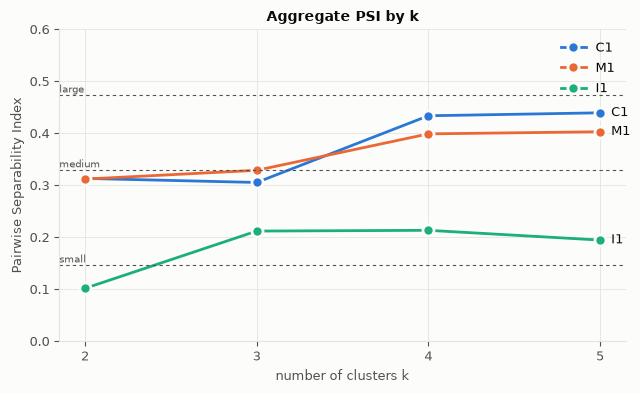

,C1 k=2,C1 k=3,C1 k=4,C1 k=5,M1 k=2,M1 k=3,M1 k=4,M1 k=5,I1 k=2,I1 k=3,I1 k=4,I1 k=5
Age,0.062 (N),0.046 (N),0.265 (S),0.251 (S),0.053 (N),0.245 (S),0.263 (S),0.305 (S),0.140 (N),0.306 (S),0.263 (S),0.228 (S)
MMSE,0.082 (N),0.070 (N),0.373 (M),0.411 (M),0.091 (N),0.128 (N),0.368 (M),0.303 (S),0.040 (N),0.169 (S),0.137 (N),0.151 (S)
nWBV,0.144 (N),0.254 (S),0.445 (M),0.401 (M),0.184 (S),0.264 (S),0.480 (L),0.320 (S),0.094 (N),0.390 (M),0.318 (S),0.273 (S)
eTIV,0.697 (L),0.550 (L),0.451 (M),0.419 (M),0.584 (L),0.422 (M),0.315 (S),0.319 (S),0.098 (N),0.191 (S),0.296 (S),0.230 (S)
CDR,0.002 (N),0.092 (N),0.346 (M),0.350 (M),0.042 (N),0.086 (N),0.356 (M),0.255 (S),0.022 (N),0.159 (S),0.134 (N),0.098 (N)
Educ,0.412 (M),0.502 (L),0.593 (L),0.614 (L),0.509 (L),0.477 (L),0.544 (L),0.716 (L),0.174 (S),0.167 (S),0.129 (N),0.168 (S)
SES,0.448 (M),0.532 (L),0.674 (L),0.651 (L),0.453 (M),0.559 (L),0.559 (L),0.685 (L),0.114 (N),0.168 (S),0.154 (S),0.186 (S)
sex,0.660 (L),0.396 (M),0.323 (S),0.418 (M),0.579 (L),0.448 (M),0.307 (S),0.321 (S),0.131 (N),0.145 (N),0.275 (S),0.222 (S)
PSI (mean),0.313 (S),0.305 (S),0.434 (M),0.439 (M),0.312 (S),0.329 (S),0.399 (M),0.403 (M),0.102 (N),0.212 (S),0.213 (S),0.195 (S)


In [4]:
psi = pd.concat([psi_column(df, results[(n, k)]["labels"], f"{n} k={k}")
                 for n in cfg.K_SELECTION_CONFIGS for k in cfg.K_CANDIDATES], axis=1)
psi.to_csv(OUT / "psi_by_k.csv")

aggregate = pd.DataFrame({n: [psi.loc["PSI (mean)", f"{n} k={k}"] for k in cfg.K_CANDIDATES]
                          for n in cfg.K_SELECTION_CONFIGS}, index=cfg.K_CANDIDATES)
fig = psi_by_k(aggregate)
fig.savefig(OUT / "psi_by_k.png", dpi=200, bbox_inches="tight")
plt.show()
format_psi_table(psi)

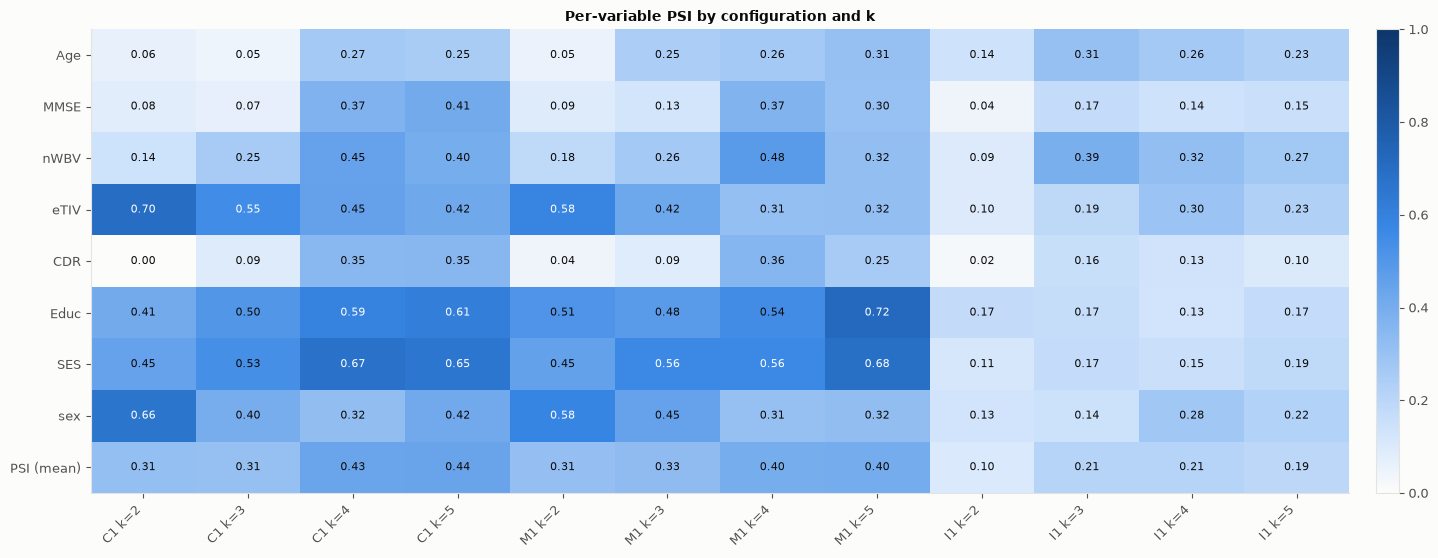

In [5]:
fig = psi_heatmap(psi, "Per-variable PSI by configuration and k")
fig.savefig(OUT / "psi_by_k_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Cluster profiles

Top row: distributions of the continuous variables (box = interquartile range, line = median,
diamond = mean). Bottom row: share of each category within each cluster.

What to look for at each k: whether the clusters differ on MMSE, CDR, nWBV and age; whether going to k + 1 adds a
new type of patient or only splits a cluster into two similar halves; and whether some clusters are very small.

### C1

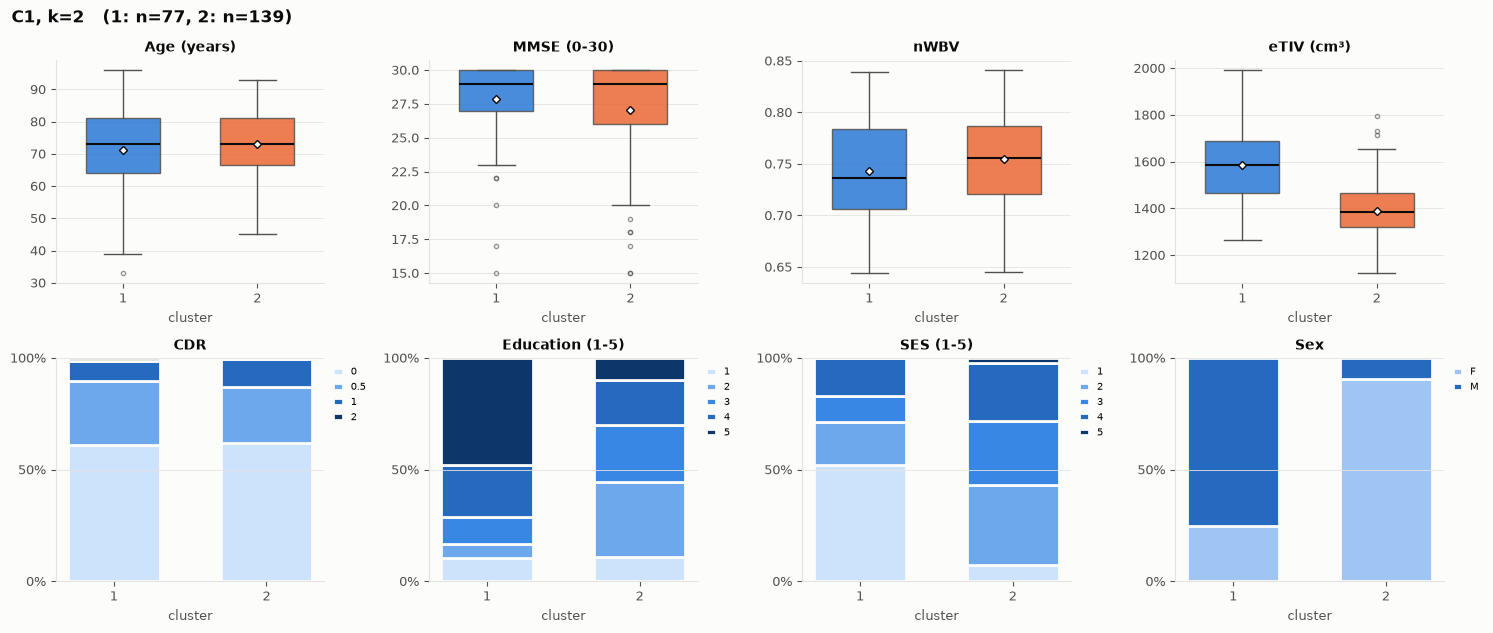

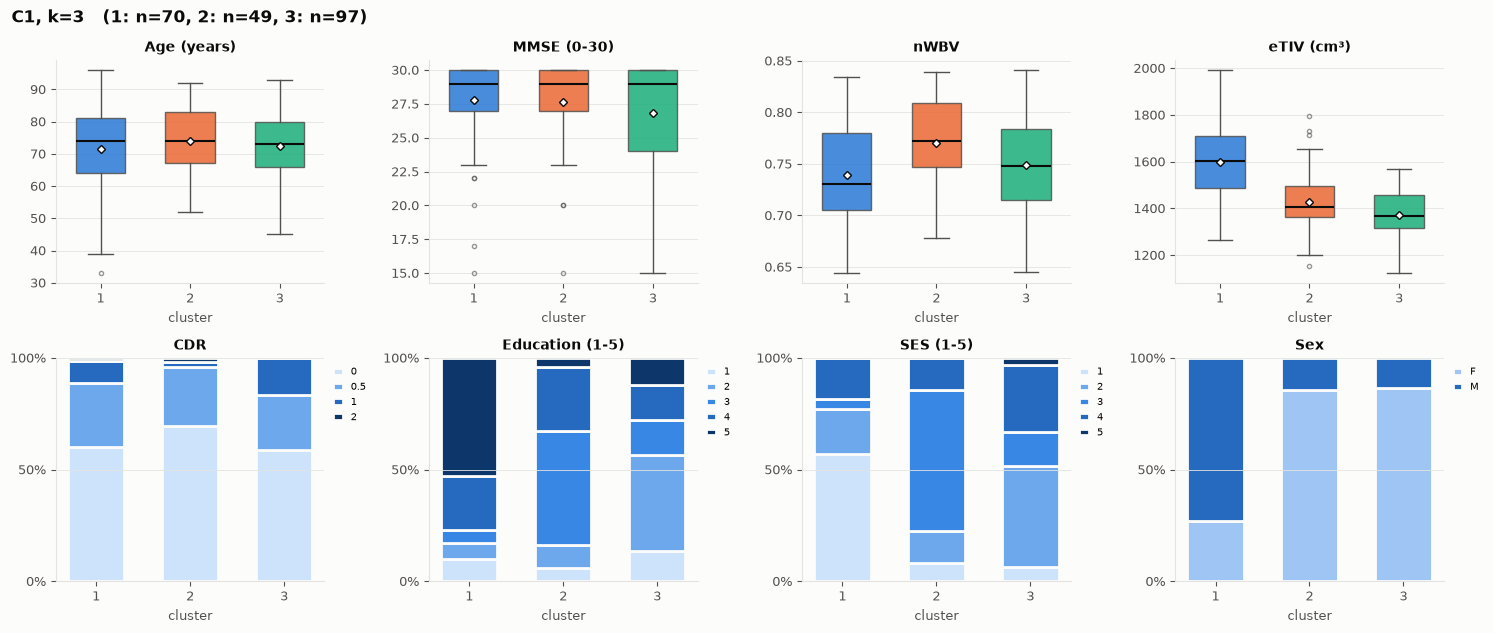

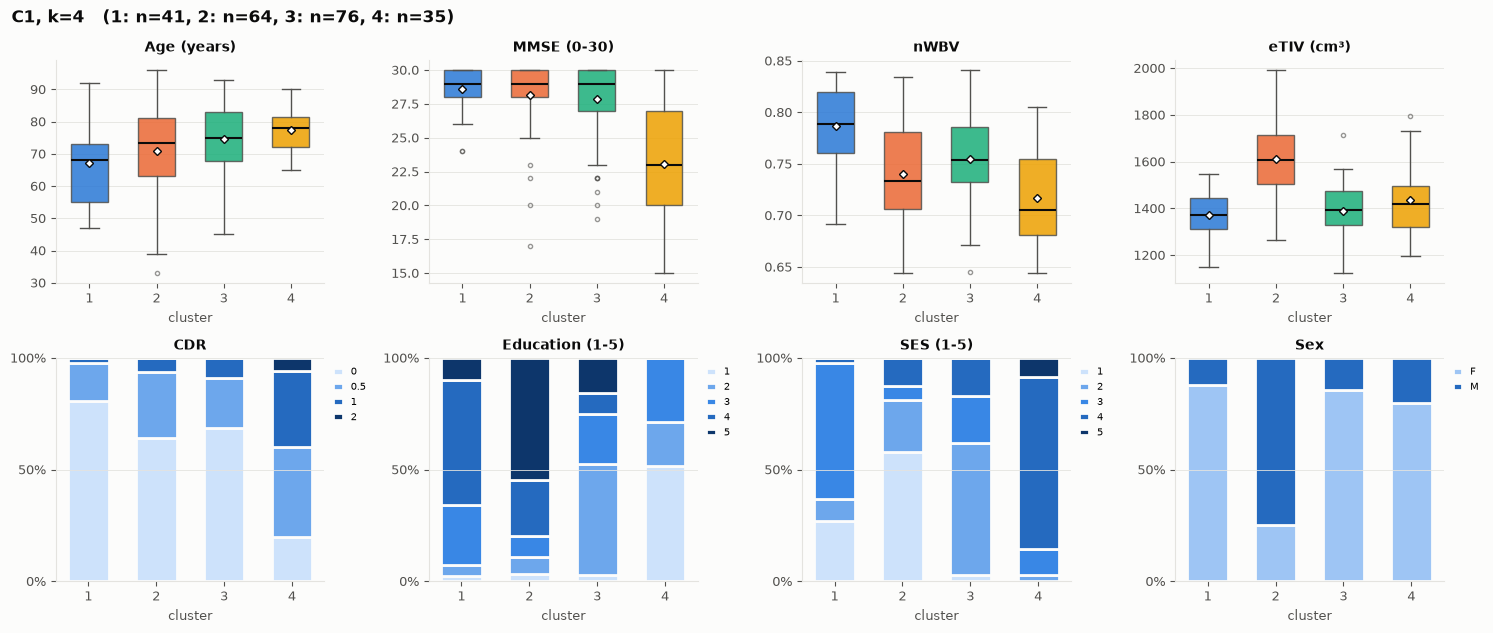

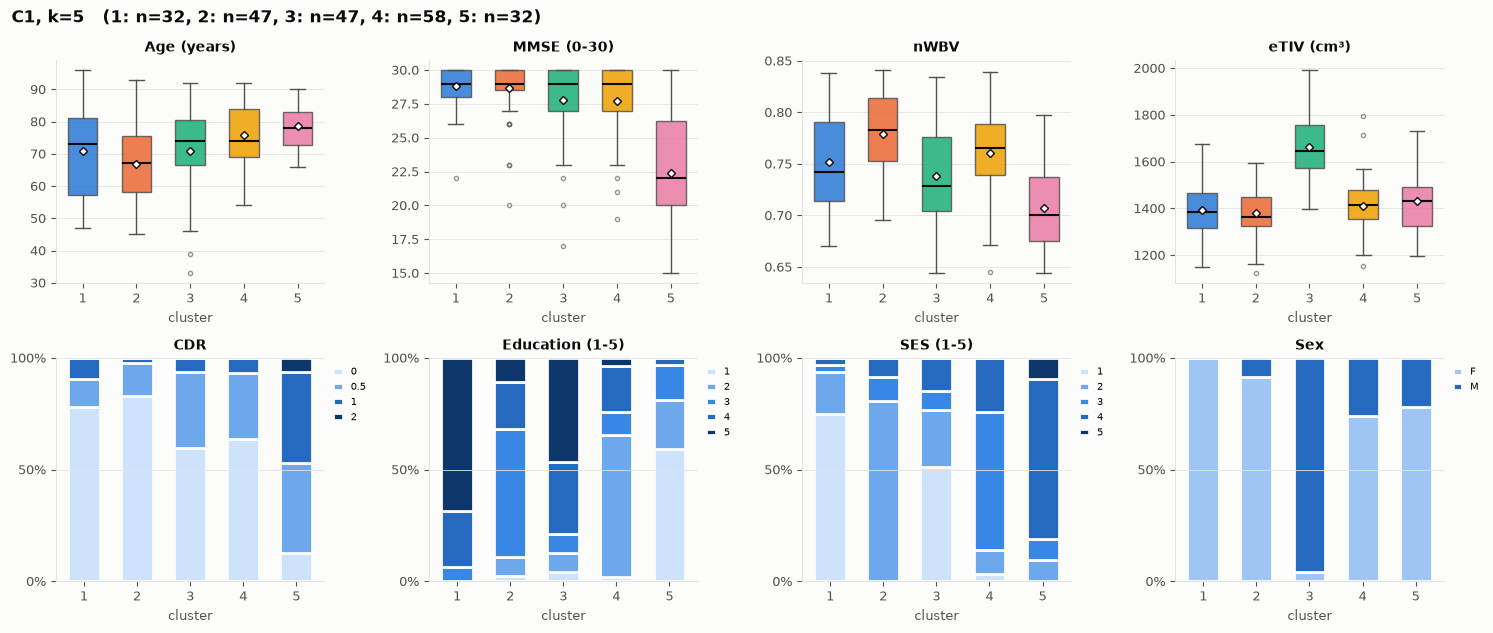

In [6]:
for k in cfg.K_CANDIDATES:
    fig = cluster_profile(df, results[("C1", k)]["labels"], f"C1, k={k}")
    fig.savefig(OUT / f"profile_C1_k{k}.png", dpi=200, bbox_inches="tight")
    plt.show()

### M1

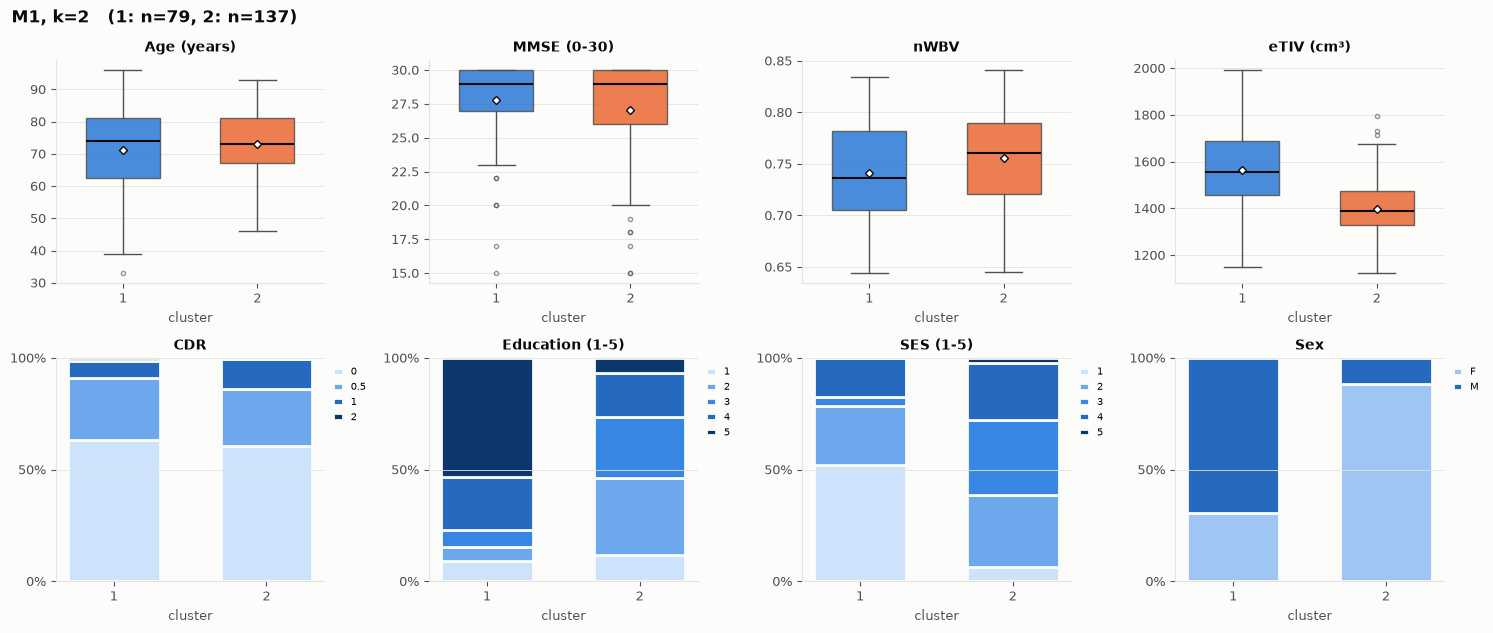

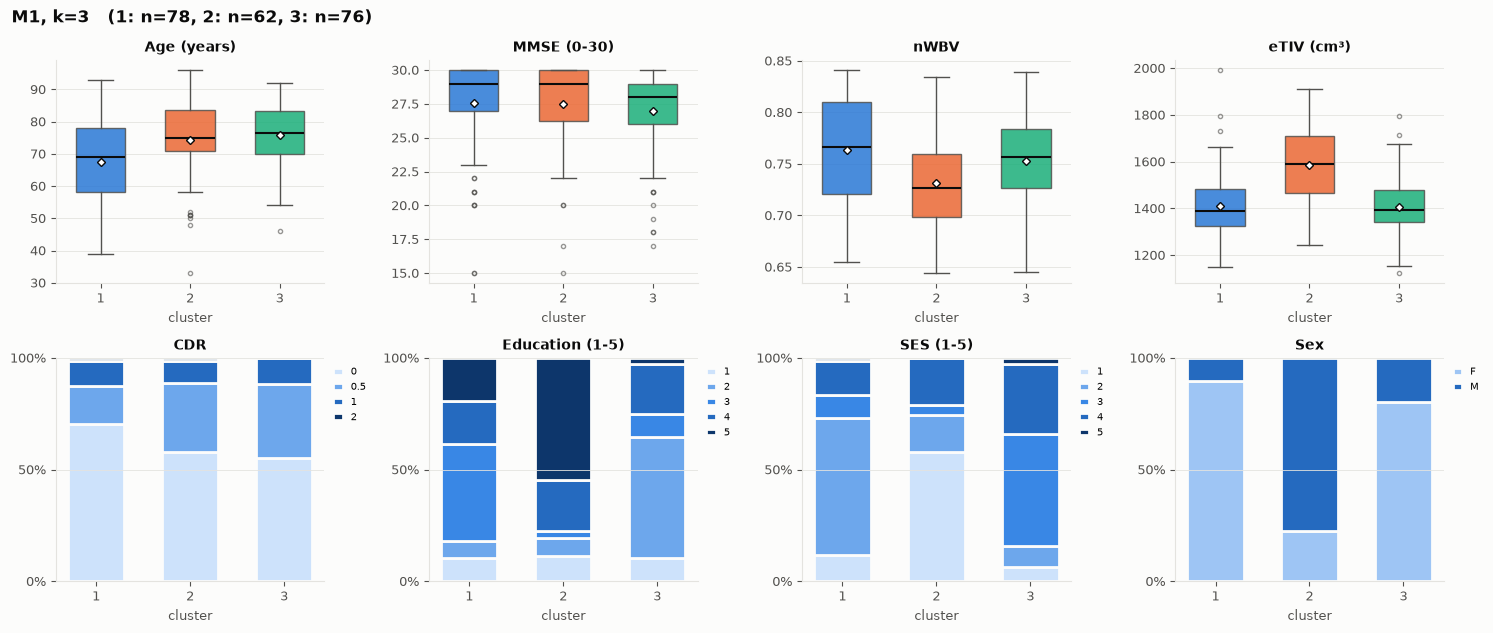

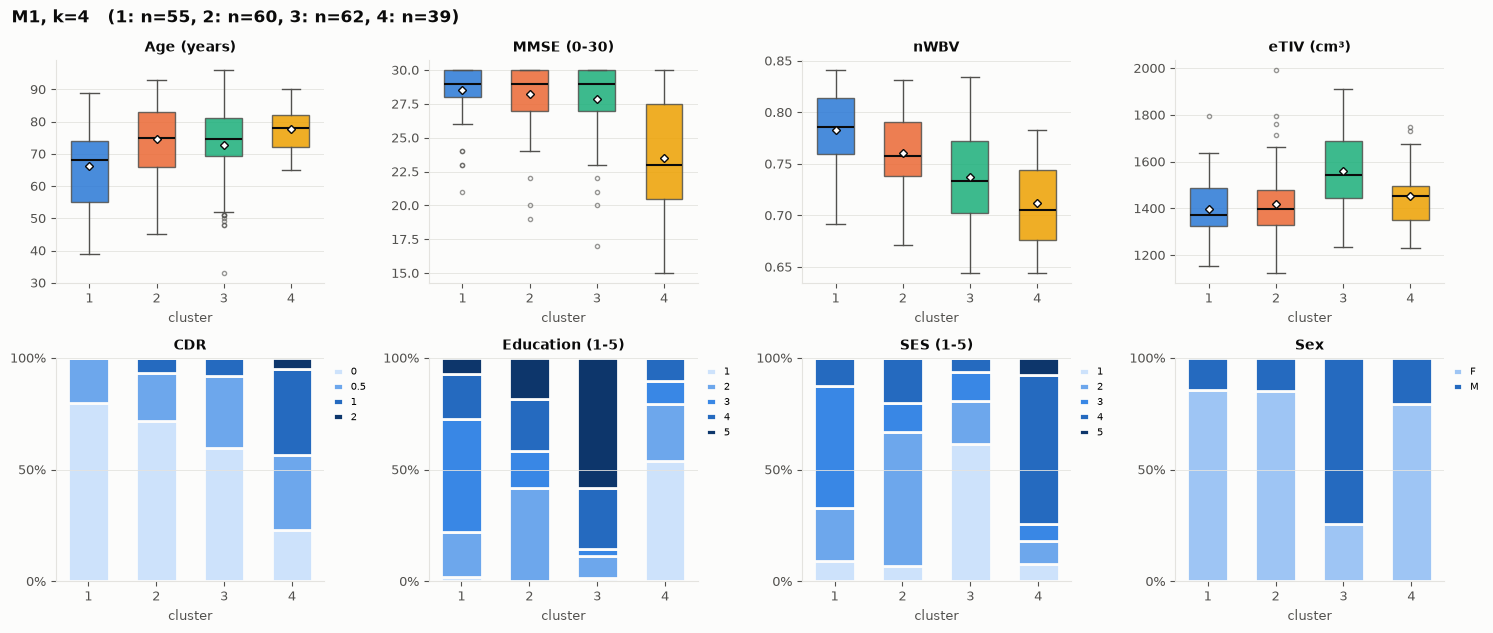

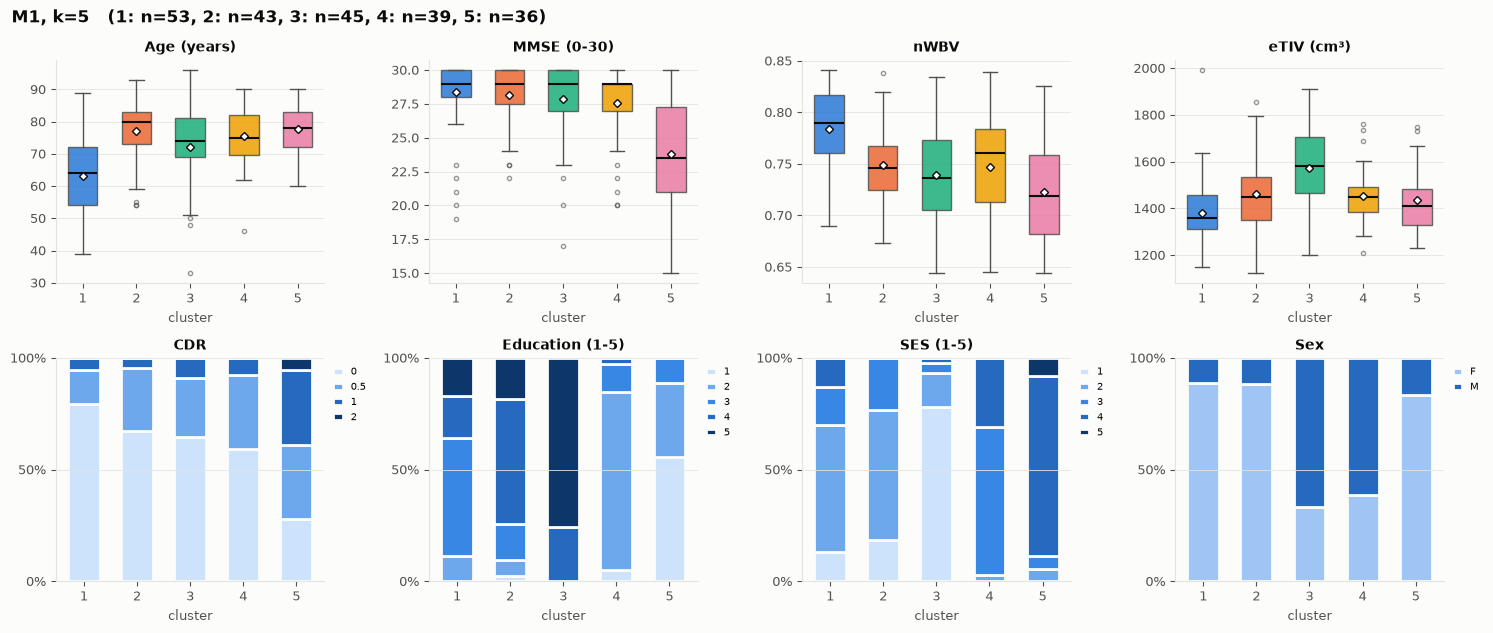

In [7]:
for k in cfg.K_CANDIDATES:
    fig = cluster_profile(df, results[("M1", k)]["labels"], f"M1, k={k}")
    fig.savefig(OUT / f"profile_M1_k{k}.png", dpi=200, bbox_inches="tight")
    plt.show()

### I1

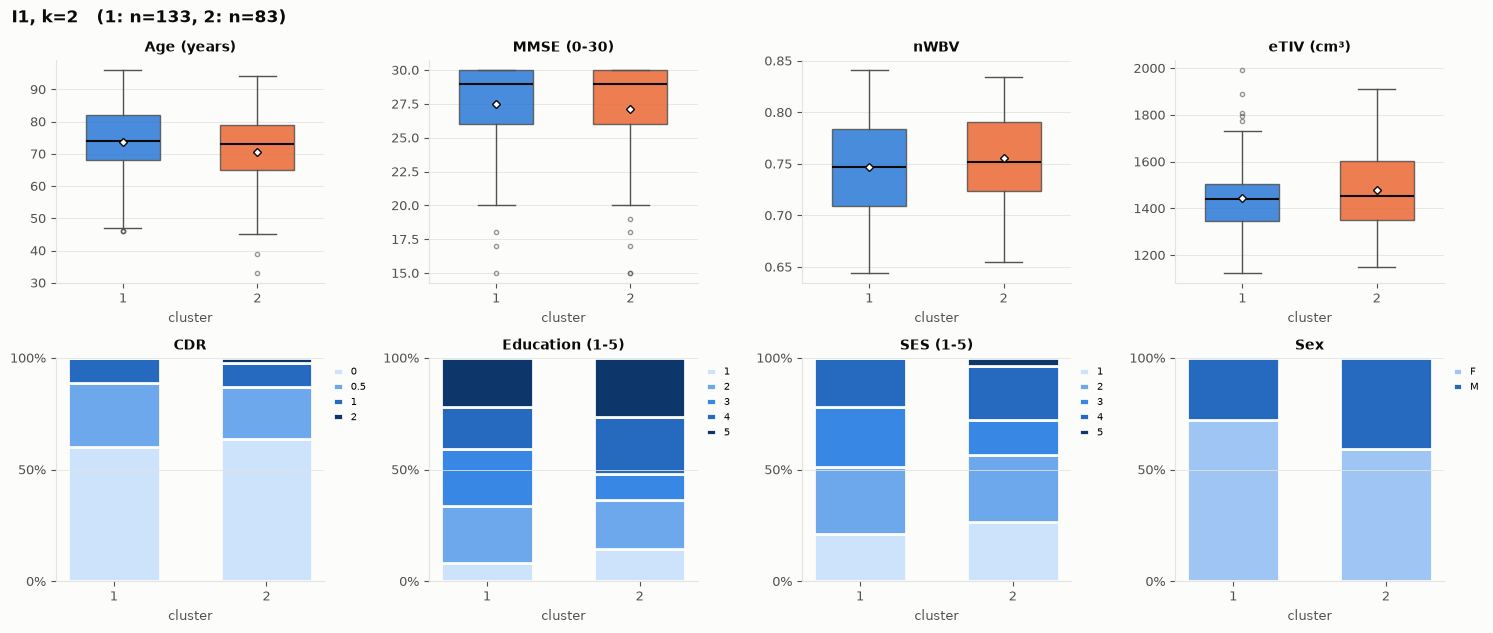

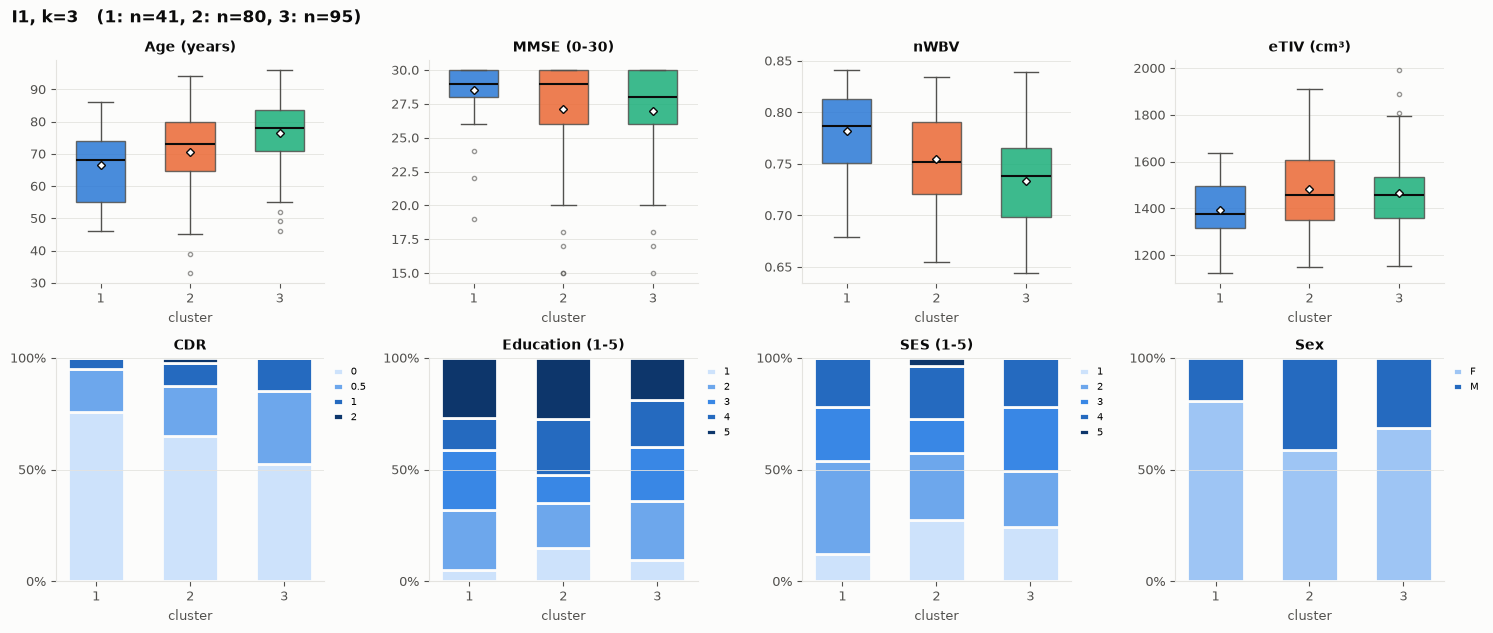

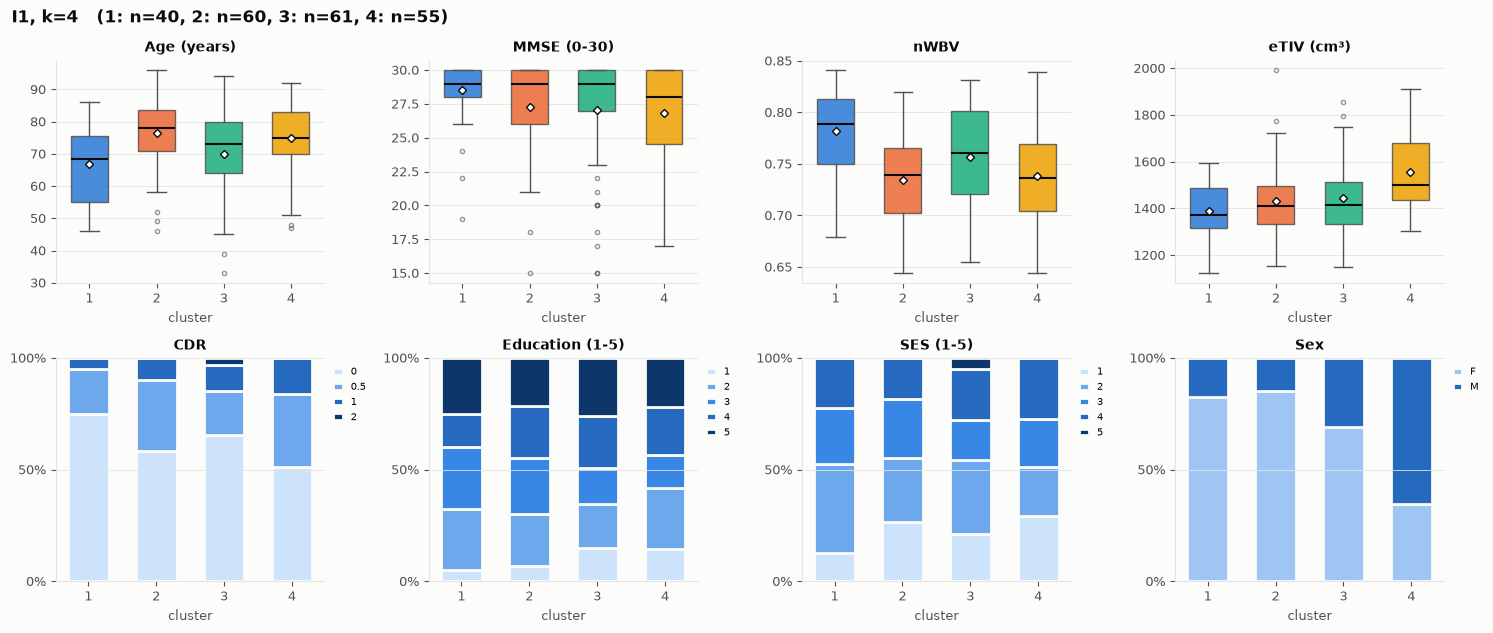

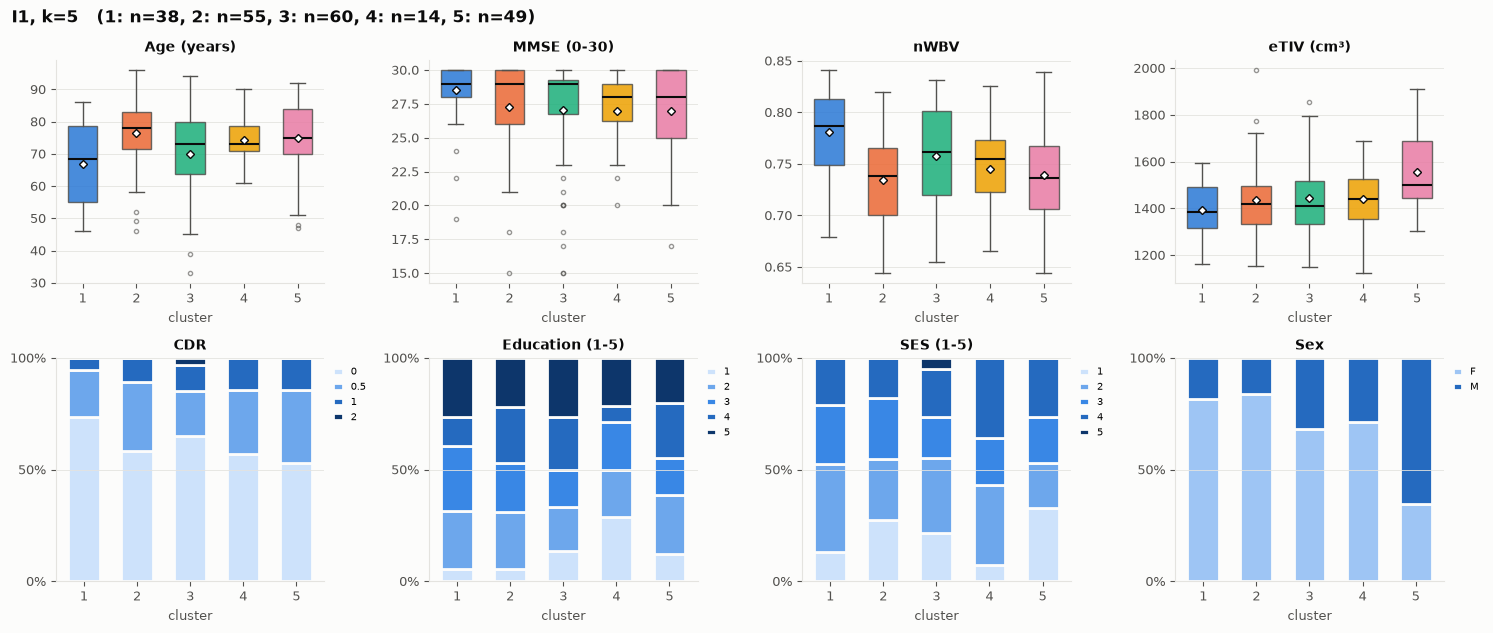

In [8]:
for k in cfg.K_CANDIDATES:
    fig = cluster_profile(df, results[("I1", k)]["labels"], f"I1, k={k}")
    fig.savefig(OUT / f"profile_I1_k{k}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 5. Medoid patients

The medoid is the real patient that represents each cluster.

In [9]:
for name in cfg.K_SELECTION_CONFIGS:
    for k in cfg.K_CANDIDATES:
        r = results[(name, k)]
        print(f"\n{name}, k={k}")
        display(medoid_table(df, r["labels"], r["medoids"]))


C1, k=2


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,77,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
1,2,139,OAS1_0237,F,72,27.0,0.0,0.764,1322,2.0,2.0



C1, k=3


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,70,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
1,2,49,OAS1_0139,F,72,28.0,0.0,0.779,1512,3.0,3.0
2,3,97,OAS1_0237,F,72,27.0,0.0,0.764,1322,2.0,2.0



C1, k=4


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,41,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,64,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
2,3,76,OAS1_0237,F,72,27.0,0.0,0.764,1322,2.0,2.0
3,4,35,OAS1_0425,F,78,23.0,1.0,0.715,1461,1.0,4.0


... (14 outputs left out)


I1, k=4


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,40,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,60,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
2,3,61,OAS1_0308,F,78,15.0,2.0,0.703,1401,3.0,3.0
3,4,55,OAS1_0016,M,82,27.0,0.5,0.739,1477,2.0,4.0



I1, k=5


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,38,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,55,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
2,3,60,OAS1_0308,F,78,15.0,2.0,0.703,1401,3.0,3.0
3,4,14,OAS1_0453,F,70,29.0,0.5,0.748,1295,1.0,4.0
4,5,49,OAS1_0016,M,82,27.0,0.5,0.739,1477,2.0,4.0


## 6. Elbow curve and silhouette

The elbow curve has no clear bend (for C1 the total distance falls by 16%, 7%, 6%, 7% and 3% as clusters 2 to 6
are added). The silhouette of C1 is highest at k = 2 (0.18) and around 0.10–0.13 afterwards, and it is about 0.01
for M1 and 0.02 for I1. The two-cluster solution of C1 separates mainly sex and head size (see the PSI by k
above), so a higher silhouette does not mean a more meaningful partition. The patients form a continuum rather
than separate groups, so neither criterion can choose k on its own. Each curve uses its configuration's own
distance, so only the shapes can be compared between configurations.

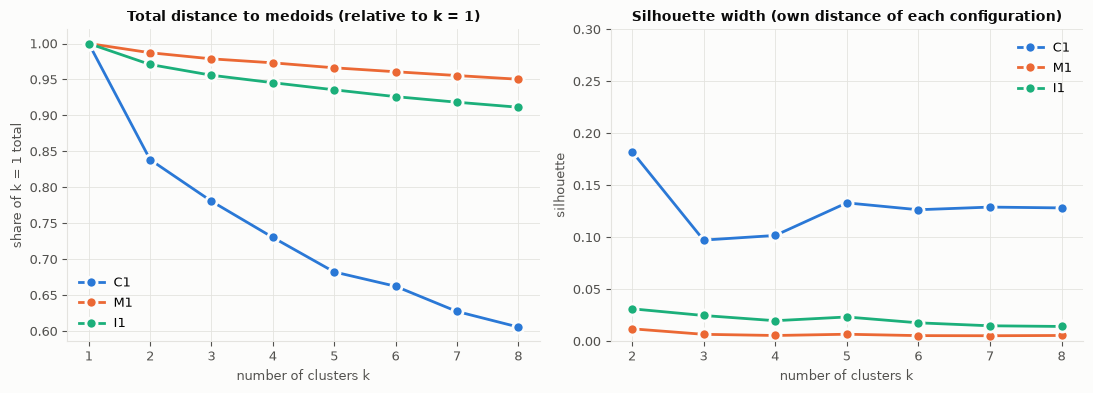

% decrease in total distance when adding one cluster:


,C1,M1,I1
1->2,16.1,1.3,2.9
2->3,6.9,0.9,1.5
3->4,6.4,0.6,1.1
4->5,6.6,0.7,1.0
5->6,2.9,0.6,1.0
6->7,5.3,0.6,0.8
7->8,3.5,0.5,0.8


In [10]:
from sklearn.metrics import silhouette_score

ks = range(1, 9)
cost, sil = {}, {}
for name in cfg.K_SELECTION_CONFIGS:
    D = results[(name, 2)]["D"]
    cost[name], sil[name] = [D.sum(axis=1).min()], []
    for k in ks[1:]:
        r = results.get((name, k)) or fit_configuration(name, k, df)
        cost[name].append(D[np.arange(len(D)), r["medoids"][np.argmin(D[:, r["medoids"]], axis=1)]].sum())
        sil[name].append(silhouette_score(D, r["labels"], metric="precomputed"))
cost = pd.DataFrame(cost, index=list(ks))
sil = pd.DataFrame(sil, index=list(ks)[1:])

fig = elbow_and_silhouette(cost, sil)
fig.savefig(OUT / "elbow_silhouette.png", dpi=200, bbox_inches="tight")
plt.show()
print("% decrease in total distance when adding one cluster:")
(-cost.pct_change() * 100).iloc[1:].round(1).rename(index=lambda k: f"{k-1}->{k}")

## 7. Decision: k = 4

Reasoning for the clinical reference configuration C1 (medians per cluster in brackets):

| k | Limitation | What the clusters show | Decision |
|---|---|---|---|
| 2 | split by sex and head size only | eTIV PSI 0.70 and sex 0.66, but MMSE 0.08 and CDR 0.00 | rejected |
| 3 | no impaired cluster | all three clusters have median MMSE 29; they differ in sex, head size and education | rejected |
| **4** | – | younger, healthy, larger brain volume (68 y, mostly women) · mostly men with large heads and high education (75% men) · lower education, mostly women · cognitively impaired (MMSE 23, 80% CDR > 0) | **selected**: first k with a cognitively impaired cluster; PSI 0.43, with MMSE 0.37 and CDR 0.35 |
| 5 | split by sex | adds a cluster with 0% men and one with 96% men; PSI almost unchanged (0.439 vs 0.434) | rejected |

M1 shows the same pattern: at k = 4 it also has an impaired cluster (77% CDR > 0), and k = 5 mainly splits by sex
and education. I1 is weak at every k (PSI ≤ 0.21).

`K = 4` is set in `src/config.ipynb`.